In [1]:
import pandas as pd

In [ ]:
df = pd.read_csv("heart.csv")
print(df.shape)
df.head()

(918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


In [4]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [5]:
df["HeartDisease"].value_counts()

HeartDisease
1    508
0    410
Name: count, dtype: int64

In [6]:
print((df["Cholesterol"] == 0).sum())
print((df["RestingBP"] == 0).sum())

172
1


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("heart.csv")

In [ ]:
df["Cholesterol"] = df["Cholesterol"].replace(0, np.nan)
df["Cholesterol"] = df["Cholesterol"].fillna(df["Cholesterol"].median())
df["RestingBP"] = df["RestingBP"].replace(0, np.nan)
df["RestingBP"] = df["RestingBP"].fillna(df["RestingBP"].median())
print((df["Cholesterol"] == 0).sum(), (df["RestingBP"] == 0).sum())

0 0


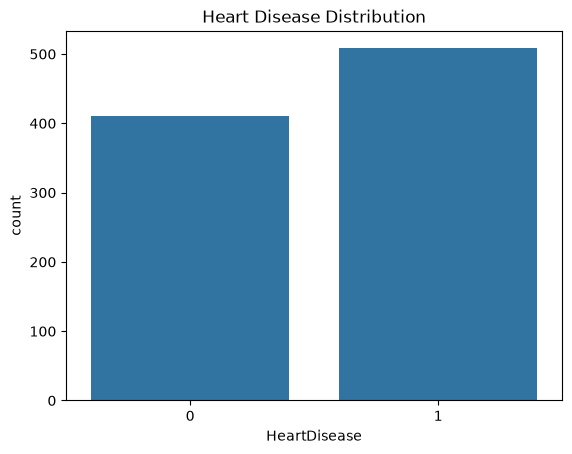

In [20]:
sns.countplot(x="HeartDisease", data=df)
plt.title("Heart Disease Distribution")
plt.show()

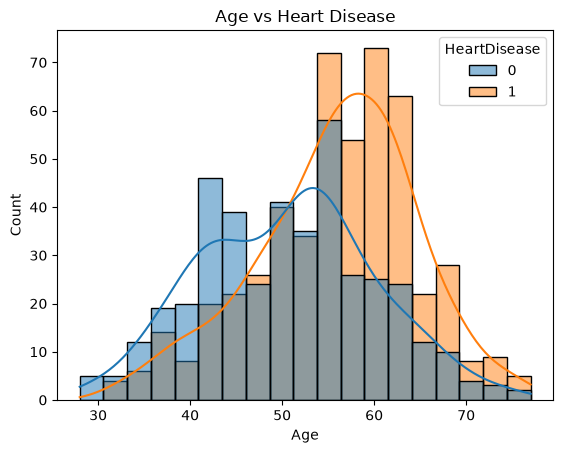

In [21]:
sns.histplot(data=df, x="Age", hue="HeartDisease", kde=True)
plt.title("Age vs Heart Disease")
plt.show()

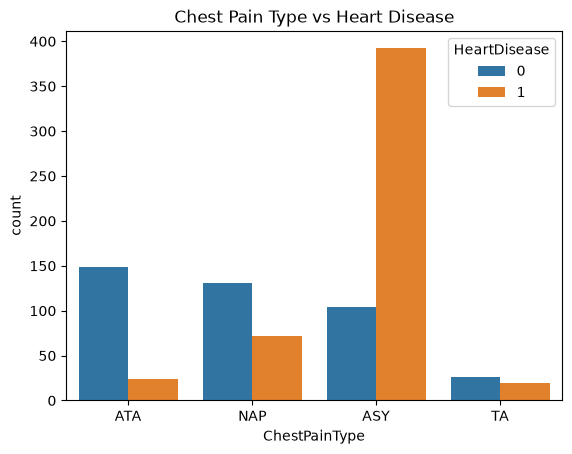

In [22]:
sns.countplot(x="ChestPainType", hue="HeartDisease", data=df)
plt.title("Chest Pain Type vs Heart Disease")
plt.show()

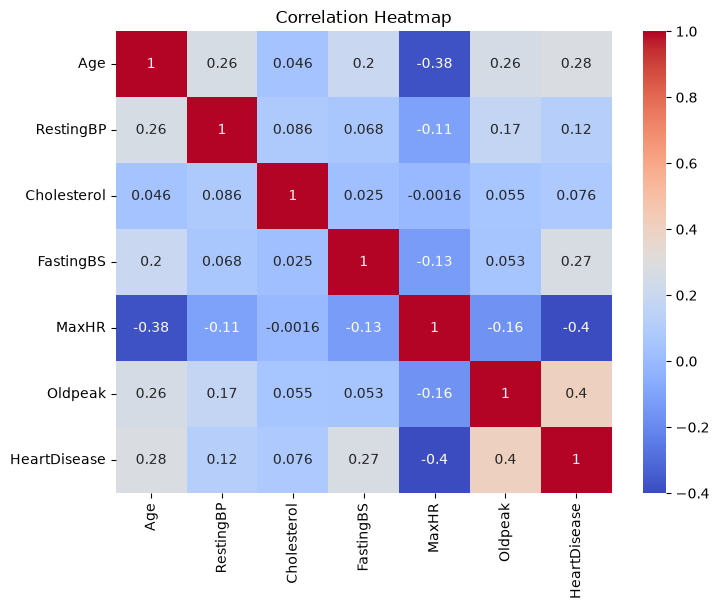

In [23]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [24]:
df.to_csv("heart_clean.csv", index=False)

In [25]:
#Encoding
df = pd.read_csv("heart_clean.csv")
df_encoded = pd.get_dummies(df, drop_first=True)
print(df_encoded.shape)
df_encoded.head()

(918, 16)


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140.0,289.0,0,172,0.0,0,True,True,False,False,True,False,False,False,True
1,49,160.0,180.0,0,156,1.0,1,False,False,True,False,True,False,False,True,False
2,37,130.0,283.0,0,98,0.0,0,True,True,False,False,False,True,False,False,True
3,48,138.0,214.0,0,108,1.5,1,False,False,False,False,True,False,True,True,False
4,54,150.0,195.0,0,122,0.0,0,True,False,True,False,True,False,False,False,True


In [30]:
from sklearn.model_selection import train_test_split
X = df_encoded.drop("HeartDisease", axis=1)
y = df_encoded["HeartDisease"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(734, 15) (184, 15)


In [33]:
#Scaling
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [34]:
#model train
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
lr = LogisticRegression(max_iter=1000)
rf = RandomForestClassifier(n_estimators=200, random_state=42)
xgb = XGBClassifier(eval_metric="logloss", random_state=42)
lr.fit(X_train_scaled, y_train)
rf.fit(X_train, y_train)
xgb.fit(X_train, y_train)
print("Training done!")

Training done!


In [35]:
#1results
from sklearn.metrics import accuracy_score
print("Logistic Regression:", accuracy_score(y_test, lr.predict(X_test_scaled)))
print("Random Forest:", accuracy_score(y_test, rf.predict(X_test)))
print("XGBoost:", accuracy_score(y_test, xgb.predict(X_test)))

Logistic Regression: 0.8913043478260869
Random Forest: 0.8532608695652174
XGBoost: 0.8586956521739131


In [37]:
#Comparison table
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
models = {
    "Logistic Regression": (lr, X_test_scaled),
    "Random Forest": (rf, X_test),
    "XGBoost": (xgb, X_test),
}
rows = []
for name, (model, Xt) in models.items():
    pred = model.predict(Xt)
    prob = model.predict_proba(Xt)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })

results = pd.DataFrame(rows).round(3)
results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.891,0.894,0.912,0.903,0.933
1,Random Forest,0.853,0.871,0.863,0.867,0.931
2,XGBoost,0.859,0.880,0.863,0.871,0.914


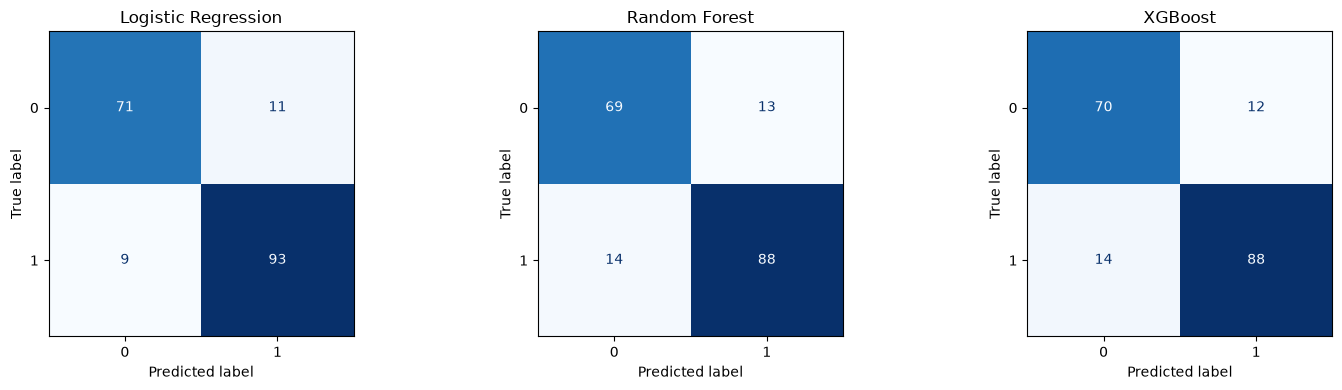

In [38]:
#Confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, (model, Xt)) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(model, Xt, y_test, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [39]:
#Cross-validation
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=42),
}
for name, m in cv_models.items():
    scores = cross_val_score(m, X, y, cv=cv, scoring="recall")
    print(f"{name}: Recall mean = {scores.mean():.3f} (+/- {scores.std():.3f})")

Logistic Regression: Recall mean = 0.884 (+/- 0.040)
Random Forest: Recall mean = 0.908 (+/- 0.026)
XGBoost: Recall mean = 0.874 (+/- 0.025)


In [40]:
#Result save
results.to_csv("model_results.csv", index=False)

In [41]:
#SHAP install check
import shap
print(shap.__version__)

c:\Users\samim\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


0.54.1


In [43]:
#SHAP values
X_test_f = X_test.astype(float)
explainer = shap.TreeExplainer(rf)
sv = explainer(X_test_f)
sv1 = sv[:, :, 1] if sv.values.ndim == 3 else sv
print(sv1.values.shape)

(184, 15)


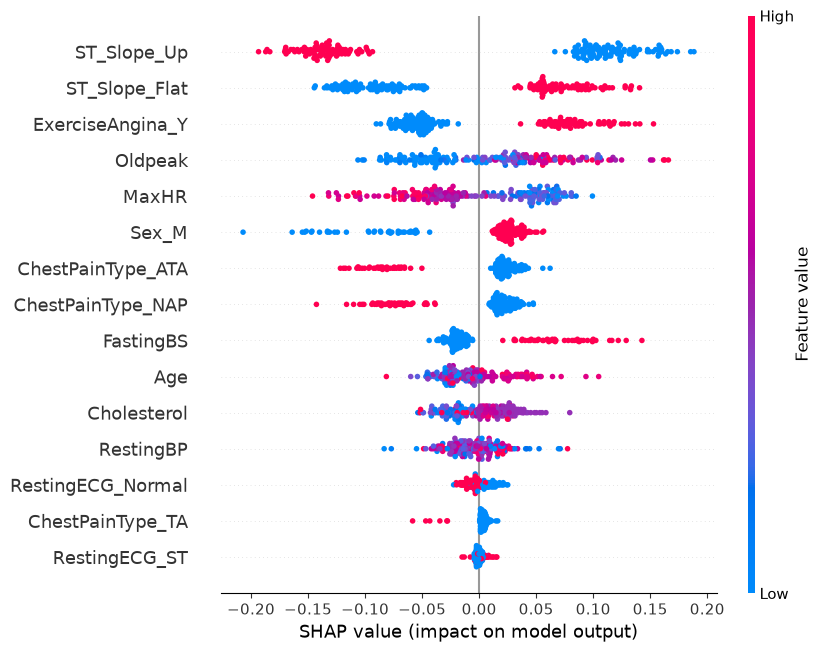

In [44]:
#Summary plot
shap.plots.beeswarm(sv1, max_display=15)

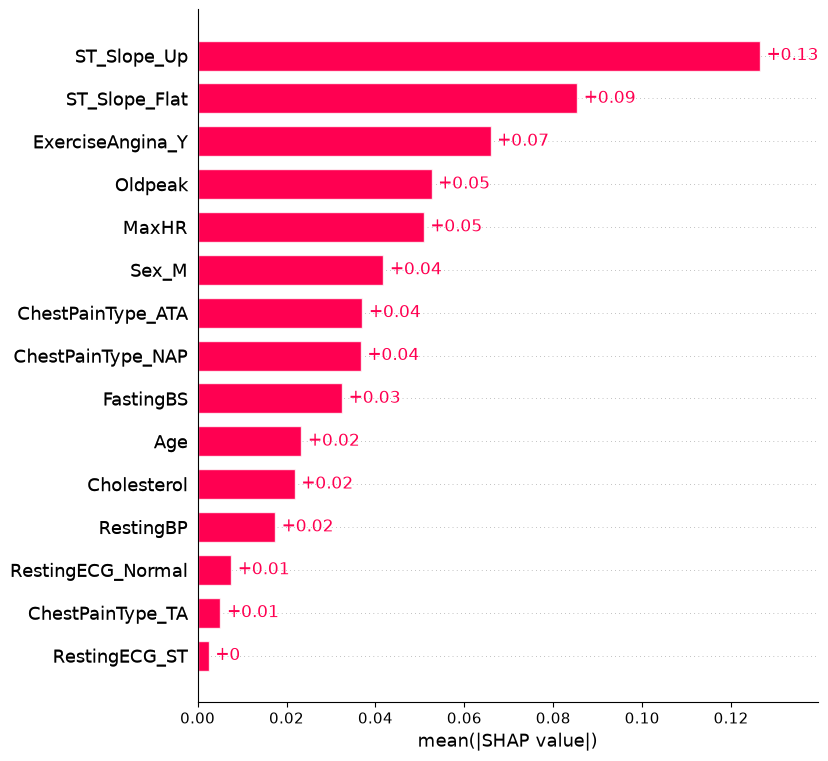

In [45]:
#Feature importance bar plot
shap.plots.bar(sv1, max_display=15)

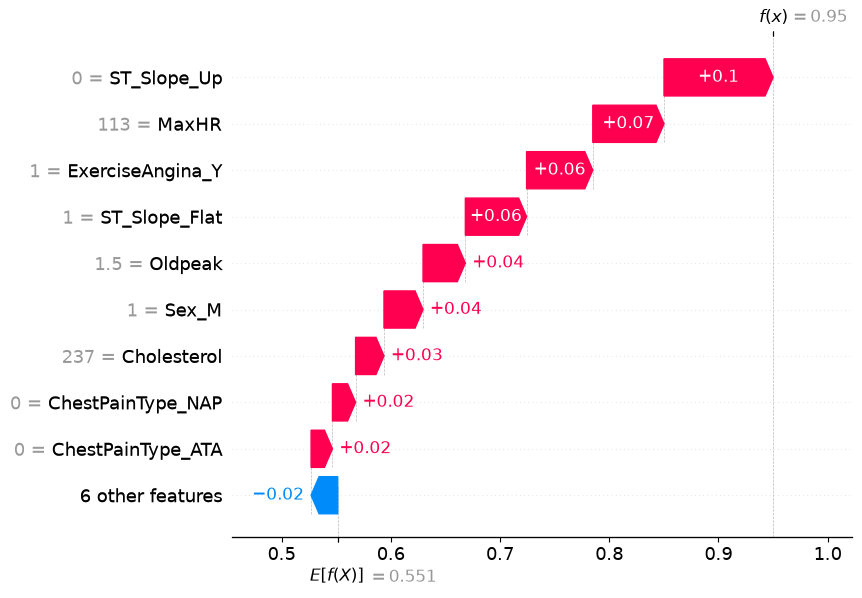

In [46]:
#A patients prediction explanation
shap.plots.waterfall(sv1[0])

In [47]:
#Model save
import joblib
joblib.dump(rf, "model.pkl")
joblib.dump(list(X.columns), "columns.pkl")
print("Saved!")

Saved!


In [49]:
# SHAP summary
plt.figure()
shap.plots.beeswarm(sv1, max_display=15, show=False)
plt.savefig("shap_summary.png", dpi=150, bbox_inches="tight")
plt.close()

# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, (model_, Xt)) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(model_, Xt, y_test, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.close()

In [4]:
df = pd.read_csv("heart_clean.csv")

print("Overall disease rate:", round(df["HeartDisease"].mean() * 100, 1), "%\n")

for col in ["ChestPainType", "Sex", "ExerciseAngina", "ST_Slope", "FastingBS"]:
    print(f"--- Disease rate (%) by {col} ---")
    print((df.groupby(col)["HeartDisease"].mean() * 100).round(1), "\n")

print("--- Mean values by HeartDisease (0 = normal, 1 = disease) ---")
print(df.groupby("HeartDisease")[["Age", "MaxHR", "Oldpeak", "Cholesterol", "RestingBP"]].mean().round(1))

Overall disease rate: 55.3 %

--- Disease rate (%) by ChestPainType ---
ChestPainType
ASY    79.0
ATA    13.9
NAP    35.5
TA     43.5
Name: HeartDisease, dtype: float64 

--- Disease rate (%) by Sex ---
Sex
F    25.9
M    63.2
Name: HeartDisease, dtype: float64 

--- Disease rate (%) by ExerciseAngina ---
ExerciseAngina
N    35.1
Y    85.2
Name: HeartDisease, dtype: float64 

--- Disease rate (%) by ST_Slope ---
ST_Slope
Down    77.8
Flat    82.8
Up      19.7
Name: HeartDisease, dtype: float64 

--- Disease rate (%) by FastingBS ---
FastingBS
0    48.0
1    79.4
Name: HeartDisease, dtype: float64 

--- Mean values by HeartDisease (0 = normal, 1 = disease) ---
               Age  MaxHR  Oldpeak  Cholesterol  RestingBP
HeartDisease                                              
0             50.6  148.2      0.4        238.7      130.2
1             55.9  127.7      1.3        246.9      134.4


In [5]:
print((df.groupby("ST_Slope")["HeartDisease"].mean() * 100).round(1))
print((df.groupby("FastingBS")["HeartDisease"].mean() * 100).round(1))

ST_Slope
Down    77.8
Flat    82.8
Up      19.7
Name: HeartDisease, dtype: float64
FastingBS
0    48.0
1    79.4
Name: HeartDisease, dtype: float64
